In [1]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.12.14 (main, Aug 12 2026, 13:57:54) [Clang 21.0.0 (clang-2100.1.1.101)]
Python executable: /Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/.venv/bin/python


In [2]:
import torch
import torchvision
import ultralytics
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Ultralytics:", ultralytics.__version__)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/Users/shreyas/Library/Application Support/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
PyTorch: 2.15.0
Torchvision: 0.29.2
Ultralytics: 8.4.202
OpenCV: 5.0.0
NumPy: 2.5.4
Pandas: 3.1.0


In [3]:
import torch

print("PyTorch version:", torch.__version__)
print("MPS built:", torch.backends.mps.is_built())
print("MPS available:", torch.backends.mps.is_available())

if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Using Apple GPU:", device)
else:
    device = torch.device("cpu")
    print("Using CPU:", device)

PyTorch version: 2.15.0
MPS built: True
MPS available: True
Using Apple GPU: mps


In [4]:
import torch

device = torch.device("mps")

# Create two tensors on the Apple GPU
a = torch.rand(3, 3, device=device)
b = torch.rand(3, 3, device=device)

# Perform matrix multiplication
result = torch.matmul(a, b)

print("Device:", result.device)
print("Result:\n", result)

Device: mps:0
Result:
 tensor([[0.9171, 0.6676, 1.0712],
        [1.1362, 0.9929, 1.5114],
        [0.8894, 0.7186, 1.1426]], device='mps:0')


# 1. Dataset Analysis

## 1.1 Class ID and Category Mapping

The dataset contains images and corresponding YOLO-format
annotation files. This section investigates the relationship
between annotation class IDs and waste categories.

In [5]:
from pathlib import Path
from collections import defaultdict, Counter
import re

labels_dir = Path("../data/raw/GarbageDataset/labels")

mapping = defaultdict(Counter)

for file in labels_dir.glob("*.txt"):

    match = re.match(r"([a-zA-Z]+)", file.name)

    if not match:
        continue

    category = match.group(1).lower()

    for line in file.read_text().splitlines():

        if line.strip():
            class_id = line.split()[0]
            mapping[class_id][category] += 1

for class_id, categories in sorted(mapping.items(), key=lambda x: int(x[0])):

    print(f"Class ID {class_id}: {categories.most_common()}")

Class ID 0: [('biodegradable', 44905), ('glass', 333), ('metal', 112), ('cardboard', 31), ('paper', 18), ('plastic', 8)]
Class ID 1: [('cardboard', 4372), ('biodegradable', 224), ('paper', 69), ('glass', 30), ('metal', 2), ('plastic', 1)]
Class ID 2: [('glass', 7719), ('biodegradable', 72), ('metal', 11), ('plastic', 4), ('paper', 3)]
Class ID 3: [('metal', 4328), ('glass', 1386), ('biodegradable', 112), ('plastic', 10), ('paper', 3), ('cardboard', 2)]
Class ID 4: [('paper', 4181), ('biodegradable', 139), ('cardboard', 62), ('plastic', 5), ('glass', 3)]
Class ID 5: [('plastic', 5187), ('glass', 626), ('biodegradable', 71), ('cardboard', 37), ('paper', 18), ('metal', 6)]


In [6]:
CLASS_NAMES = [
    "biodegradable",
    "cardboard",
    "glass",
    "metal",
    "paper",
    "plastic"
]

In [7]:
from collections import Counter

mixed_files = []

for file in labels_dir.glob("*.txt"):

    class_ids = []

    for line in file.read_text().splitlines():

        if line.strip():
            class_ids.append(line.split()[0])

    unique_classes = set(class_ids)

    if len(unique_classes) > 1:
        mixed_files.append((file.name, Counter(class_ids)))

print("Files containing multiple classes:", len(mixed_files))

for filename, counts in mixed_files[:10]:
    print(filename, counts)

Files containing multiple classes: 1066
glass439_jpg.rf.057f5e3e6027a54ed35c4d2beffdeb7e.txt Counter({'2': 2, '3': 2})
glass2389_jpg.rf.882e32221319a9772fd0f0ce4e57c989.txt Counter({'2': 3, '3': 3})
glass629_jpg.rf.28220e7c7fa61cd85b8b2292750d0824.txt Counter({'2': 3, '3': 3})
glass1329_jpg.rf.03ad507e5495a5bfc8e5505e95697430.txt Counter({'2': 3, '5': 3})
glass829_jpg.rf.3399e9489faf986f36f1bde2c357048e.txt Counter({'2': 4, '3': 4, '1': 2})
cardboard608_jpg.rf.2fe299e22eaad743c57afc0d32547e4f.txt Counter({'1': 8, '0': 6})
glass1150_jpg.rf.5f2ff7593fff808ec2d292ab43efaa0f.txt Counter({'2': 1, '3': 1})
glass916_jpg.rf.bf45f5223a0c7239c34de53187c31776.txt Counter({'2': 1, '3': 1})
glass564_jpg.rf.2e83b872464ed869387f297ad37d0935.txt Counter({'2': 4, '5': 4})
plastic624_jpg.rf.5867ea61e9d1701550927c1bc0c667c8.txt Counter({'5': 1, '2': 1})


In [8]:
from pathlib import Path

# Dataset folders
images_dir = Path("../data/raw/GarbageDataset/images")
labels_dir = Path("../data/raw/GarbageDataset/labels")

# Get all image and annotation files
image_files = list(images_dir.glob("*.jpg"))
label_files = list(labels_dir.glob("*.txt"))

# Compare filenames without extensions
image_names = {file.stem for file in image_files}
label_names = {file.stem for file in label_files}

# Find unmatched files
images_without_labels = image_names - label_names
labels_without_images = label_names - image_names

# Display results
print("DATASET SUMMARY")
print("------------------------------")
print("Total images:", len(image_files))
print("Total annotation files:", len(label_files))
print("Images without labels:", len(images_without_labels))
print("Labels without images:", len(labels_without_images))

DATASET SUMMARY
------------------------------
Total images: 10464
Total annotation files: 10464
Images without labels: 0
Labels without images: 0


## 2. Image Dimensions Analysis

We inspect image dimensions to understand the resolution and variation across the dataset.

In [9]:
from PIL import Image
from collections import Counter

dimensions = Counter()

for image_path in image_files:
    with Image.open(image_path) as img:
        dimensions[img.size] += 1

print("IMAGE DIMENSIONS")
print("------------------------------")

for size, count in dimensions.most_common(10):
    print(f"{size[0]} x {size[1]}: {count} images")

print("\nTotal unique image dimensions:", len(dimensions))

IMAGE DIMENSIONS
------------------------------
416 x 416: 10464 images

Total unique image dimensions: 1


## 3. Visual Dataset Inspection

We visualize sample images to understand object appearance, background complexity, and bounding-box annotations.

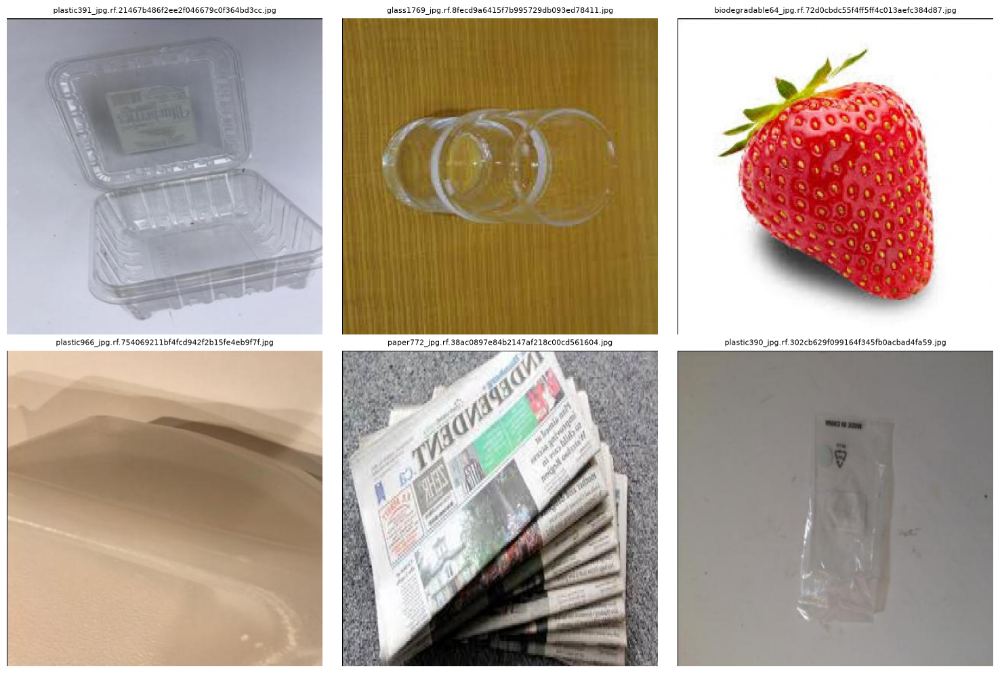

In [11]:
import matplotlib.pyplot as plt
import random

# Select 6 random images
random_images = random.sample(image_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, image_path in zip(axes.flat, random_images):

    with Image.open(image_path) as img:
        ax.imshow(img)

    ax.set_title(image_path.name, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4. Visualizing Bounding Box Annotations

We convert YOLO-format normalized bounding-box coordinates into pixel coordinates and visualize the annotated objects.

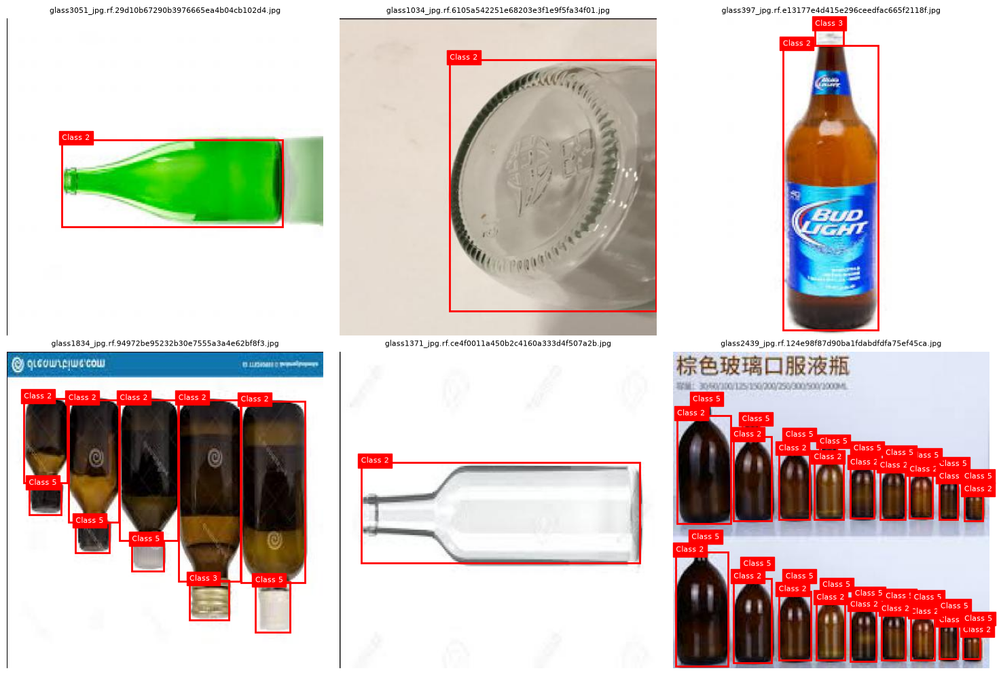

In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import random

# Select 6 random images
random_images = random.sample(image_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, image_path in zip(axes.flat, random_images):

    # Load image
    img = Image.open(image_path)
    width, height = img.size

    ax.imshow(img)

    # Find corresponding annotation
    label_path = labels_dir / (image_path.stem + ".txt")

    # Read annotations
    with open(label_path, "r") as file:
        for line in file:

            values = line.strip().split()

            class_id = int(values[0])
            x_center, y_center, box_width, box_height = map(float, values[1:5])

            # Convert normalized coordinates into pixels
            x_center *= width
            y_center *= height
            box_width *= width
            box_height *= height

            # Calculate top-left corner
            x_min = x_center - box_width / 2
            y_min = y_center - box_height / 2

            # Draw bounding box
            rectangle = patches.Rectangle(
                (x_min, y_min),
                box_width,
                box_height,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rectangle)
            ax.text(x_min, y_min, f"Class {class_id}", color="white",
                    backgroundcolor="red", fontsize=8)

    ax.set_title(image_path.name, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Objects Per Image Analysis

We calculate the number of annotated objects in each image to understand the distribution of objects across the dataset.

In [14]:
from collections import Counter

objects_per_image = []

for label_path in label_files:

    with open(label_path, "r") as file:
        object_count = sum(1 for line in file if line.strip())

    objects_per_image.append(object_count)

# Count images by number of objects
distribution = Counter(objects_per_image)

print("OBJECTS PER IMAGE")
print("------------------------------")

for count, images in sorted(distribution.items()):
    print(f"{count} object(s): {images} images")

print("\nAverage objects per image:", 
      round(sum(objects_per_image) / len(objects_per_image), 2))

print("Maximum objects in one image:", max(objects_per_image))

OBJECTS PER IMAGE
------------------------------
1 object(s): 5081 images
2 object(s): 1569 images
3 object(s): 711 images
4 object(s): 485 images
5 object(s): 275 images
6 object(s): 333 images
7 object(s): 167 images
8 object(s): 198 images
9 object(s): 102 images
10 object(s): 159 images
11 object(s): 92 images
12 object(s): 124 images
13 object(s): 54 images
14 object(s): 72 images
15 object(s): 47 images
16 object(s): 47 images
17 object(s): 41 images
18 object(s): 36 images
19 object(s): 30 images
20 object(s): 40 images
21 object(s): 33 images
22 object(s): 32 images
23 object(s): 30 images
24 object(s): 39 images
25 object(s): 25 images
26 object(s): 18 images
27 object(s): 23 images
28 object(s): 18 images
29 object(s): 22 images
30 object(s): 16 images
31 object(s): 13 images
32 object(s): 20 images
33 object(s): 20 images
34 object(s): 13 images
35 object(s): 10 images
36 object(s): 20 images
37 object(s): 12 images
38 object(s): 18 images
39 object(s): 10 images
40 object(s

In [15]:
# Store the number of objects for each annotation file
image_object_counts = []

for label_path in label_files:
    with open(label_path, "r") as file:
        count = sum(1 for line in file if line.strip())

    image_object_counts.append((label_path.stem, count))

# Sort from highest to lowest
image_object_counts.sort(key=lambda x: x[1], reverse=True)

print("TOP 10 IMAGES WITH MOST OBJECTS")
print("--------------------------------")

for filename, count in image_object_counts[:10]:
    print(f"{filename}: {count} objects")

TOP 10 IMAGES WITH MOST OBJECTS
--------------------------------
biodegradable2166_jpeg.rf.7b649a31ebc54f2d1df322d4ebe6975d: 358 objects
biodegradable1998_jpeg.rf.17921ee65cee3e00f10a24d639dff35b: 321 objects
biodegradable461_jpg.rf.b0eb9e7a6b2cf6d626ed37405af0ee6d: 311 objects
biodegradable574_jpg.rf.3ced71fe05523bc833aa5e5d62b9cf92: 293 objects
biodegradable875_jpg.rf.5dedea23fde8c40d01ac795d8b49b5de: 271 objects
biodegradable266_jpg.rf.2fcae11ba74ff12f6336491e10b07344: 245 objects
biodegradable565_jpg.rf.61a3ff21ce32f361b9289b2667e5aa44: 234 objects
glass2269_jpg.rf.4d46c78a096bbe2b28c97930c8d8fae8: 229 objects
biodegradable421_jpg.rf.0d8bc76989848c2d9173e3c49c133867: 228 objects
biodegradable452_jpg.rf.1df2910bbe3dc5b348f92d01168f45c2: 222 objects


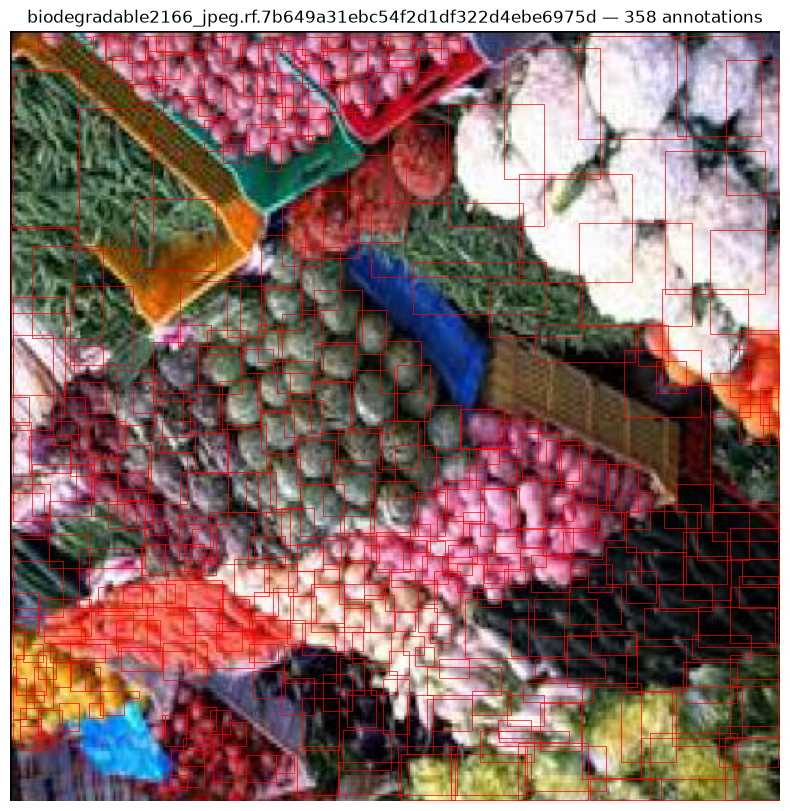

In [16]:
# Get the image with the most annotations
top_filename = image_object_counts[0][0]

image_path = images_dir / f"{top_filename}.jpg"
label_path = labels_dir / f"{top_filename}.txt"

# Load image
img = Image.open(image_path)
width, height = img.size

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img)

# Draw all bounding boxes
with open(label_path, "r") as file:
    for line in file:

        values = line.strip().split()

        class_id = int(values[0])
        x_center, y_center, box_width, box_height = map(float, values[1:5])

        x_center *= width
        y_center *= height
        box_width *= width
        box_height *= height

        x_min = x_center - box_width / 2
        y_min = y_center - box_height / 2

        rectangle = patches.Rectangle(
            (x_min, y_min),
            box_width,
            box_height,
            linewidth=0.5,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rectangle)

ax.set_title(f"{top_filename} — 358 annotations")
ax.axis("off")
plt.show()

## 6. Class Distribution Analysis

We calculate the number and percentage of annotated objects belonging to each class to identify class imbalance.

CLASS DISTRIBUTION
------------------------------
Class 0: 45407 objects (61.29%)
Class 1: 4698 objects (6.34%)
Class 2: 7809 objects (10.54%)
Class 3: 5841 objects (7.88%)
Class 4: 4390 objects (5.93%)
Class 5: 5945 objects (8.02%)

Total annotated objects: 74090


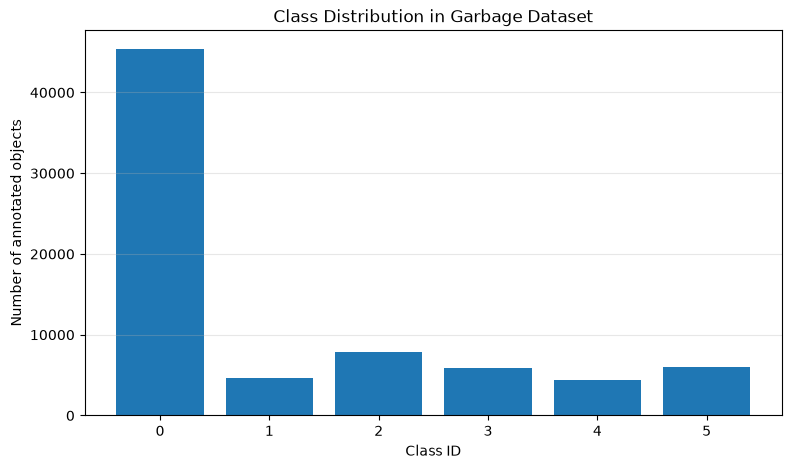

In [17]:
from collections import Counter
import matplotlib.pyplot as plt

class_counts = Counter()

for label_path in label_files:
    with open(label_path, "r") as file:
        for line in file:
            if line.strip():
                class_id = int(line.split()[0])
                class_counts[class_id] += 1

total_objects = sum(class_counts.values())

print("CLASS DISTRIBUTION")
print("------------------------------")

for class_id, count in sorted(class_counts.items()):
    percentage = (count / total_objects) * 100
    print(f"Class {class_id}: {count} objects ({percentage:.2f}%)")

print("\nTotal annotated objects:", total_objects)

# Plot class distribution
classes = sorted(class_counts.keys())
counts = [class_counts[c] for c in classes]

plt.figure(figsize=(9, 5))
plt.bar(classes, counts)
plt.xlabel("Class ID")
plt.ylabel("Number of annotated objects")
plt.title("Class Distribution in Garbage Dataset")
plt.xticks(classes)
plt.grid(axis="y", alpha=0.3)
plt.show()

## 7. Bounding Box Size Analysis

We analyze the dimensions and area of annotated objects to understand the prevalence of small, medium, and large objects.

In [19]:
import pandas as pd

bbox_data = []

for label_path in label_files:

    with open(label_path, "r") as file:

        for line in file:

            if not line.strip():
                continue

            values = line.split()

            class_id = int(values[0])
            x_center, y_center, box_width, box_height = map(float, values[1:5])

            # Convert normalized dimensions into pixels
            width_px = box_width * 416
            height_px = box_height * 416

            # Calculate bounding box area percentage
            area_percentage = box_width * box_height * 100

            bbox_data.append({
                "class_id": class_id,
                "width_px": width_px,
                "height_px": height_px,
                "area_percentage": area_percentage
            })

bbox_df = pd.DataFrame(bbox_data)

print("BOUNDING BOX SIZE SUMMARY")
print("------------------------------")
print(bbox_df[["width_px", "height_px", "area_percentage"]].describe().round(2))

BOUNDING BOX SIZE SUMMARY
------------------------------
       width_px  height_px  area_percentage
count  74090.00   74090.00         74090.00
mean      95.75     102.39             9.99
std       99.40     102.82            19.33
min        0.00       0.00             0.00
25%       29.00      31.00             0.55
50%       56.00      61.00             1.99
75%      121.00     132.00             8.82
max      416.00     416.00            99.52


## 8. Bounding Box Validation

We check for invalid bounding boxes, including zero dimensions, negative dimensions, and coordinates outside the image boundaries.

In [20]:
invalid_boxes = []

for label_path in label_files:

    with open(label_path, "r") as file:

        for line_number, line in enumerate(file, start=1):

            if not line.strip():
                continue

            values = line.split()

            class_id = int(values[0])
            x_center, y_center, box_width, box_height = map(float, values[1:5])

            reasons = []

            if box_width <= 0:
                reasons.append("Invalid width")

            if box_height <= 0:
                reasons.append("Invalid height")

            if not (0 <= x_center <= 1 and 0 <= y_center <= 1):
                reasons.append("Invalid center coordinates")

            if not (0 < box_width <= 1 and 0 < box_height <= 1):
                reasons.append("Invalid box dimensions")

            if (x_center - box_width / 2 < 0 or
                x_center + box_width / 2 > 1 or
                y_center - box_height / 2 < 0 or
                y_center + box_height / 2 > 1):
                reasons.append("Box extends outside image")

            if reasons:
                invalid_boxes.append({
                    "file": label_path.name,
                    "line": line_number,
                    "class_id": class_id,
                    "reasons": ", ".join(reasons)
                })

print("BOUNDING BOX VALIDATION")
print("------------------------------")
print("Total invalid annotations:", len(invalid_boxes))

for box in invalid_boxes[:10]:
    print(box)

BOUNDING BOX VALIDATION
------------------------------
Total invalid annotations: 17
{'file': 'cardboard1827_jpg.rf.856569da32835c8109724605187526fc.txt', 'line': 1, 'class_id': 1, 'reasons': 'Invalid width, Invalid box dimensions'}
{'file': 'paper1430_jpg.rf.4da0e71eab5e1a13f510f439c7d7fd28.txt', 'line': 9, 'class_id': 4, 'reasons': 'Invalid width, Invalid box dimensions'}
{'file': 'biodegradable2284_jpeg.rf.7f1b4eeb50bf5f036f56467382ed0a4b.txt', 'line': 7, 'class_id': 0, 'reasons': 'Invalid height, Invalid box dimensions'}
{'file': 'paper787_jpg.rf.a776cf355b31868a4cfda6ff51850600.txt', 'line': 1, 'class_id': 4, 'reasons': 'Invalid height, Invalid box dimensions'}
{'file': 'biodegradable565_jpg.rf.61a3ff21ce32f361b9289b2667e5aa44.txt', 'line': 94, 'class_id': 0, 'reasons': 'Invalid height, Invalid box dimensions'}
{'file': 'biodegradable1465_jpg.rf.6554b314de4df3aed0117f0283e9df7f.txt', 'line': 54, 'class_id': 0, 'reasons': 'Invalid height, Invalid box dimensions'}
{'file': 'biodegra

In [21]:
from collections import Counter

reason_counts = Counter()
affected_files = set()

for box in invalid_boxes:
    affected_files.add(box["file"])

    for reason in box["reasons"].split(", "):
        reason_counts[reason] += 1

print("INVALID ANNOTATION BREAKDOWN")
print("------------------------------")

for reason, count in reason_counts.items():
    print(f"{reason}: {count}")

print("\nTotal invalid annotation rows:", len(invalid_boxes))
print("Unique affected images:", len(affected_files))

INVALID ANNOTATION BREAKDOWN
------------------------------
Invalid width: 7
Invalid box dimensions: 17
Invalid height: 10

Total invalid annotation rows: 17
Unique affected images: 17


## 9. Duplicate Image Analysis

We check for exact duplicate images using MD5 hashes to reduce the risk of data leakage between training, validation, and test sets.

In [22]:
import hashlib
from collections import defaultdict

image_hashes = defaultdict(list)

for image_path in image_files:

    with open(image_path, "rb") as file:
        file_hash = hashlib.md5(file.read()).hexdigest()

    image_hashes[file_hash].append(image_path.name)

# Find duplicate groups
duplicate_groups = [
    filenames
    for filenames in image_hashes.values()
    if len(filenames) > 1
]

print("DUPLICATE IMAGE ANALYSIS")
print("------------------------------")
print("Total images:", len(image_files))
print("Unique image hashes:", len(image_hashes))
print("Duplicate groups:", len(duplicate_groups))
print("Images involved in duplicates:",
      sum(len(group) for group in duplicate_groups))

for group in duplicate_groups[:10]:
    print(group)

DUPLICATE IMAGE ANALYSIS
------------------------------
Total images: 10464
Unique image hashes: 10464
Duplicate groups: 0
Images involved in duplicates: 0


In [23]:
from collections import defaultdict

class_image_counts = defaultdict(int)

for label_path in label_files:

    classes_in_image = set()

    with open(label_path, "r") as file:
        for line in file:

            if line.strip():
                class_id = int(line.split()[0])
                classes_in_image.add(class_id)

    for class_id in classes_in_image:
        class_image_counts[class_id] += 1

print("IMAGES PER CLASS")
print("------------------------------")

for class_id in sorted(class_image_counts):
    count = class_image_counts[class_id]
    percentage = count / len(image_files) * 100

    print(f"Class {class_id}: {count} images ({percentage:.2f}%)")

IMAGES PER CLASS
------------------------------
Class 0: 2287 images (21.86%)
Class 1: 1502 images (14.35%)
Class 2: 2684 images (25.65%)
Class 3: 1898 images (18.14%)
Class 4: 1768 images (16.90%)
Class 5: 1464 images (13.99%)


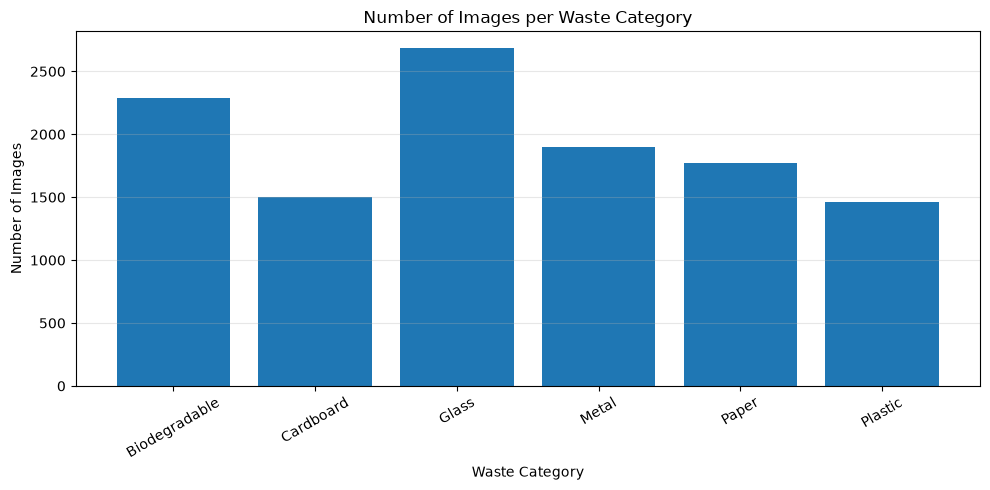

In [24]:
class_names = {
    0: "Biodegradable",
    1: "Cardboard",
    2: "Glass",
    3: "Metal",
    4: "Paper",
    5: "Plastic"
}

classes = sorted(class_image_counts.keys())

names = [class_names[c] for c in classes]
counts = [class_image_counts[c] for c in classes]

plt.figure(figsize=(10, 5))
plt.bar(names, counts)

plt.xlabel("Waste Category")
plt.ylabel("Number of Images")
plt.title("Number of Images per Waste Category")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Multi-Class Image Analysis

We investigate how many images contain one or multiple waste categories.

In [25]:
from collections import Counter

classes_per_image = Counter()

for label_path in label_files:

    classes_in_image = set()

    with open(label_path, "r") as file:
        for line in file:

            if line.strip():
                class_id = int(line.split()[0])
                classes_in_image.add(class_id)

    classes_per_image[len(classes_in_image)] += 1

print("CLASSES PER IMAGE")
print("------------------------------")

for number_of_classes, image_count in sorted(classes_per_image.items()):
    print(f"{number_of_classes} class(es): {image_count} images")

print("\nTotal images:", sum(classes_per_image.values()))

CLASSES PER IMAGE
------------------------------
1 class(es): 9398 images
2 class(es): 998 images
3 class(es): 64 images
4 class(es): 3 images
5 class(es): 1 images

Total images: 10464


In [26]:
expected_classes = set(range(6))
found_classes = set(class_counts.keys())

print("CLASS ID VALIDATION")
print("------------------------------")
print("Expected class IDs:", sorted(expected_classes))
print("Found class IDs:", sorted(found_classes))

print("Missing classes:", sorted(expected_classes - found_classes))
print("Unexpected classes:", sorted(found_classes - expected_classes))

CLASS ID VALIDATION
------------------------------
Expected class IDs: [0, 1, 2, 3, 4, 5]
Found class IDs: [0, 1, 2, 3, 4, 5]
Missing classes: []
Unexpected classes: []


## 11. Class Co-occurrence Analysis

We identify which combinations of waste categories appear together in the same image.

In [27]:
from itertools import combinations
from collections import Counter

class_pairs = Counter()

for label_path in label_files:

    classes_in_image = set()

    with open(label_path, "r") as file:
        for line in file:
            if line.strip():
                classes_in_image.add(int(line.split()[0]))

    # Count every pair of different classes
    for pair in combinations(sorted(classes_in_image), 2):
        class_pairs[pair] += 1

print("CLASS PAIR CO-OCCURRENCE")
print("------------------------------")

for pair, count in class_pairs.most_common():
    print(f"Class {pair[0]} + Class {pair[1]}: {count} images")

CLASS PAIR CO-OCCURRENCE
------------------------------
Class 2 + Class 3: 587 images
Class 2 + Class 5: 259 images
Class 0 + Class 3: 93 images
Class 0 + Class 2: 67 images
Class 3 + Class 5: 35 images
Class 0 + Class 1: 31 images
Class 0 + Class 5: 30 images
Class 0 + Class 4: 28 images
Class 1 + Class 4: 26 images
Class 1 + Class 5: 15 images
Class 4 + Class 5: 13 images
Class 1 + Class 2: 10 images
Class 1 + Class 3: 9 images
Class 3 + Class 4: 8 images
Class 2 + Class 4: 7 images


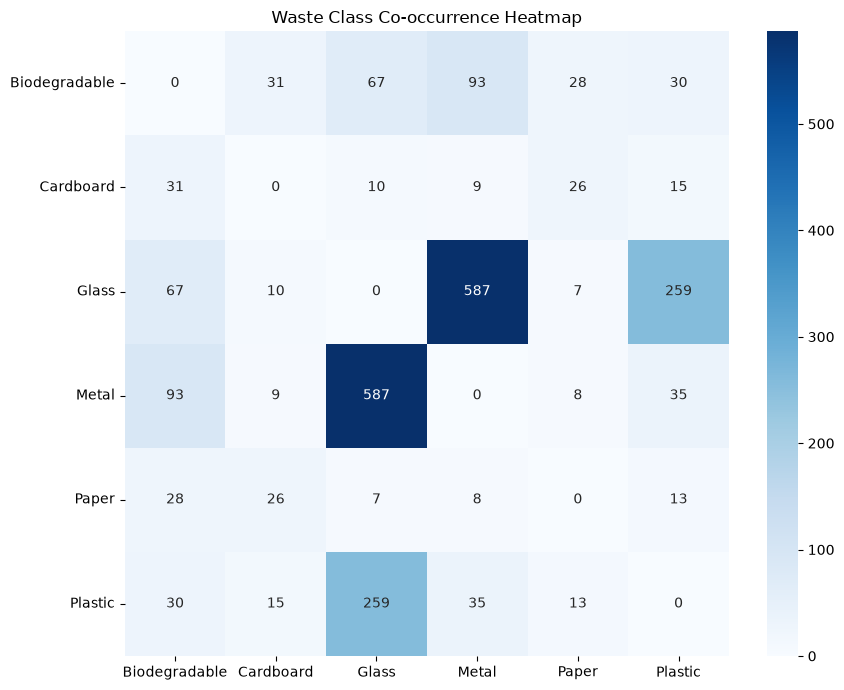

In [28]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Create a 6 x 6 matrix
cooccurrence_matrix = np.zeros((6, 6), dtype=int)

for (class_a, class_b), count in class_pairs.items():
    cooccurrence_matrix[class_a, class_b] = count
    cooccurrence_matrix[class_b, class_a] = count

# Class names
class_labels = [
    "Biodegradable",
    "Cardboard",
    "Glass",
    "Metal",
    "Paper",
    "Plastic"
]

plt.figure(figsize=(9, 7))

sns.heatmap(
    cooccurrence_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Waste Class Co-occurrence Heatmap")
plt.tight_layout()
plt.show()

## 12. Bounding Box Distribution by Class

We compare bounding-box sizes across all six classes to identify categories with predominantly small or large objects.

BOUNDING BOX AREA BY CLASS
------------------------------
          count   mean  median   min    max
class_id                                   
0         45395   4.11    1.04  0.00  99.52
1          4696  27.67   12.27  0.01  99.52
2          7809  15.45    9.24  0.01  99.52
3          5841  12.40    4.81  0.03  99.52
4          4387  34.80   19.53  0.03  99.52
5          5945  13.09    3.61  0.04  99.52


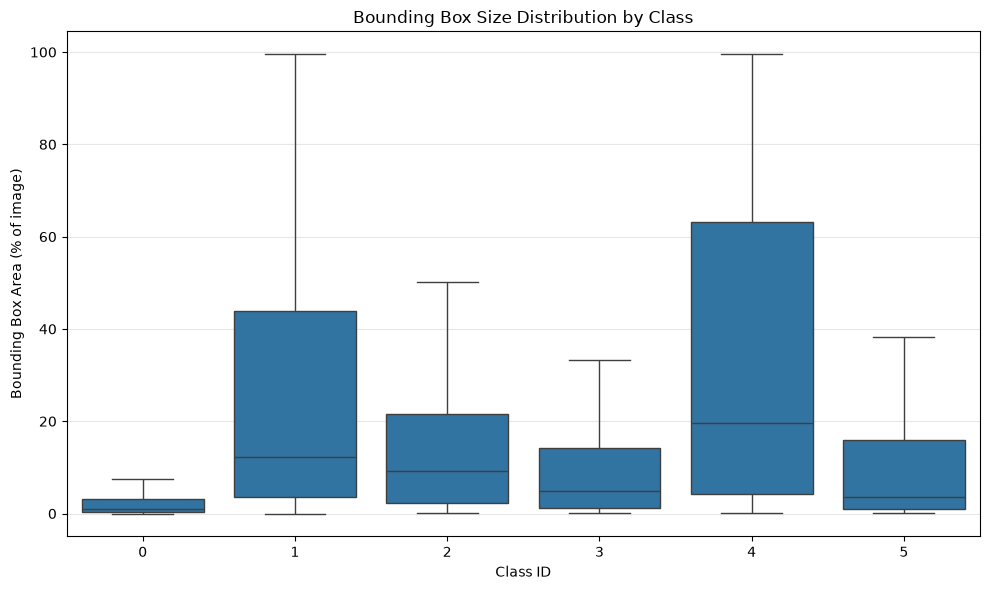

In [29]:
# Exclude invalid zero-area bounding boxes for this analysis
valid_bbox_df = bbox_df[bbox_df["area_percentage"] > 0].copy()

# Summary statistics for each class
class_bbox_summary = valid_bbox_df.groupby("class_id")["area_percentage"].agg(
    ["count", "mean", "median", "min", "max"]
)

print("BOUNDING BOX AREA BY CLASS")
print("------------------------------")
print(class_bbox_summary.round(2))

# Visualize the distributions
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=valid_bbox_df,
    x="class_id",
    y="area_percentage",
    showfliers=False
)

plt.xlabel("Class ID")
plt.ylabel("Bounding Box Area (% of image)")
plt.title("Bounding Box Size Distribution by Class")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [30]:
print("SMALLEST BOUNDING BOX AREAS")
print("------------------------------")

print(
    valid_bbox_df["area_percentage"]
    .nsmallest(10)
    .to_string(index=False)
)

print("\nBOXES SMALLER THAN 0.1% OF IMAGE:")

for class_id in sorted(valid_bbox_df["class_id"].unique()):

    count = (
        valid_bbox_df[
            (valid_bbox_df["class_id"] == class_id) &
            (valid_bbox_df["area_percentage"] < 0.1)
        ].shape[0]
    )

    print(f"Class {class_id}: {count}")
    

SMALLEST BOUNDING BOX AREAS
------------------------------
0.002311
0.003467
0.003467
0.006067
0.009101
0.009246
0.009246
0.009246
0.009246
0.009246

BOXES SMALLER THAN 0.1% OF IMAGE:
Class 0: 2012
Class 1: 36
Class 2: 96
Class 3: 62
Class 4: 4
Class 5: 58


## 13. Bounding Box Aspect Ratio Analysis

We analyze the width-to-height ratio of bounding boxes to understand the shapes of annotated objects.

ASPECT RATIO SUMMARY
------------------------------
count    74073.00
mean         1.17
std          1.02
min          0.03
25%          0.62
50%          0.93
75%          1.39
max         42.36
Name: aspect_ratio, dtype: float64


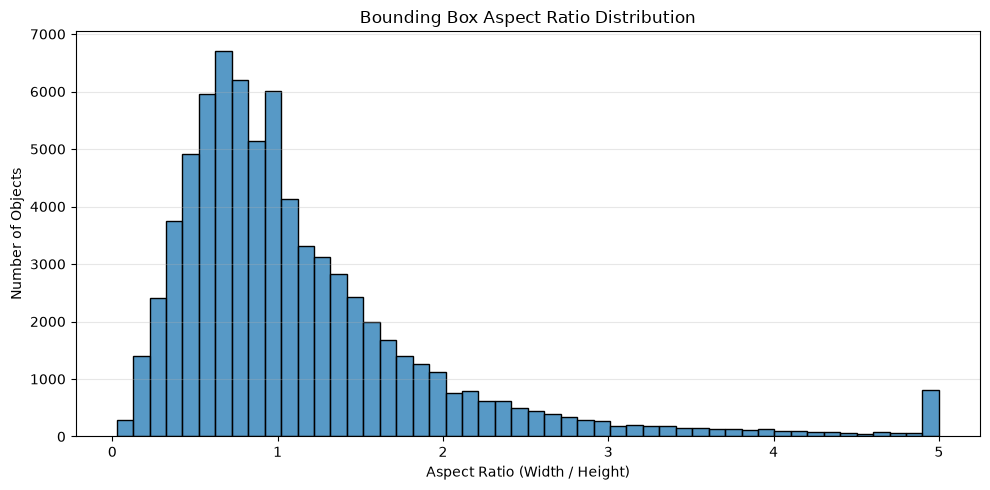

In [31]:
# Calculate aspect ratio for valid bounding boxes
valid_bbox_df["aspect_ratio"] = (
    valid_bbox_df["width_px"] / valid_bbox_df["height_px"]
)

print("ASPECT RATIO SUMMARY")
print("------------------------------")

print(valid_bbox_df["aspect_ratio"].describe().round(2))

# Visualize aspect ratios
plt.figure(figsize=(10, 5))

sns.histplot(
    valid_bbox_df["aspect_ratio"].clip(upper=5),
    bins=50
)

plt.xlabel("Aspect Ratio (Width / Height)")
plt.ylabel("Number of Objects")
plt.title("Bounding Box Aspect Ratio Distribution")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 14. Aspect Ratio Distribution by Class


We compare bounding-box aspect ratios across different class IDs to identify differences in object shapes.

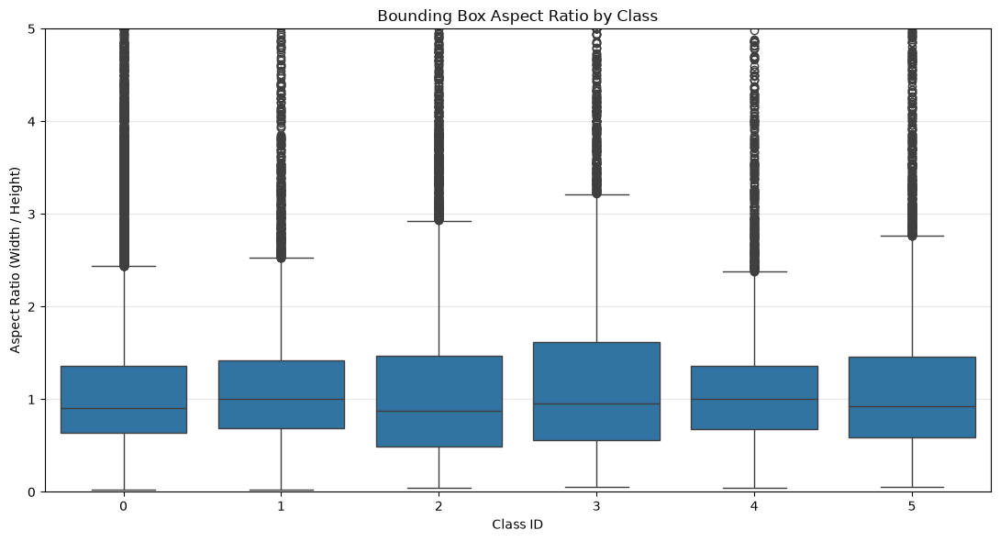

In [33]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=valid_bbox_df,
    x="class_id",
    y="aspect_ratio"
)

plt.ylim(0, 5)
plt.xlabel("Class ID")
plt.ylabel("Aspect Ratio (Width / Height)")
plt.title("Bounding Box Aspect Ratio by Class")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 15. Visual Inspection of Annotated Images

We visualize sample images with their ground-truth bounding boxes and class IDs to assess annotation quality.

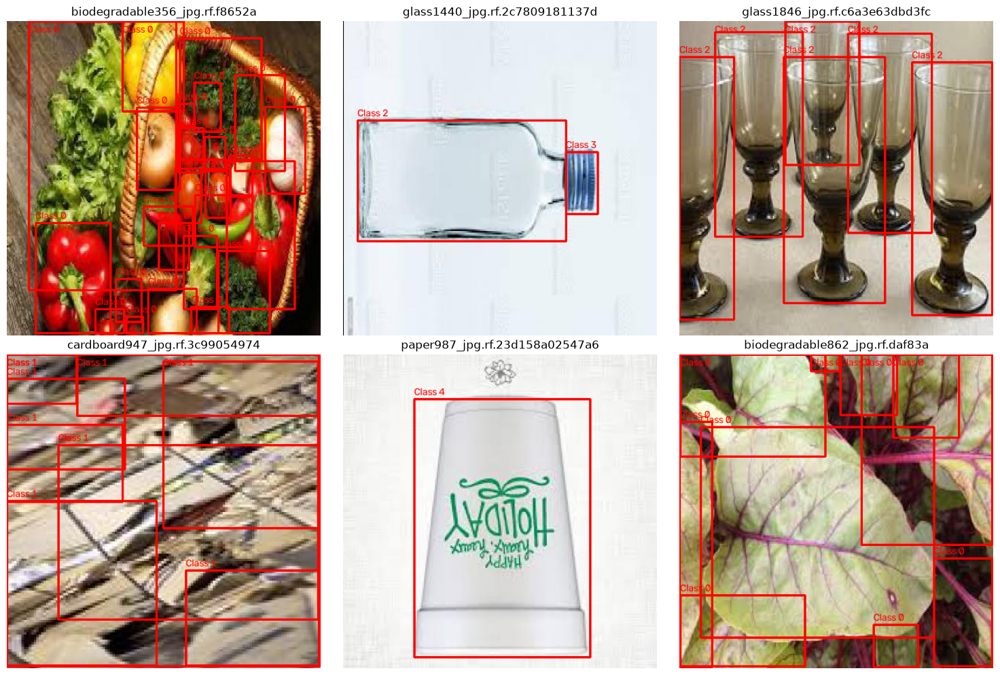

In [34]:
import random
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

images_dir = Path("../data/raw/GarbageDataset/images")
labels_dir = Path("../data/raw/GarbageDataset/labels")

image_files = list(images_dir.glob("*.jpg"))

# Select 6 random images
random.seed(42)
sample_images = random.sample(image_files, 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for ax, image_path in zip(axes, sample_images):

    # Load image
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Find corresponding label file
    label_path = labels_dir / f"{image_path.stem}.txt"

    # Draw bounding boxes
    for line in label_path.read_text().splitlines():

        values = line.split()

        if len(values) != 5:
            continue

        class_id, x_center, y_center, width, height = map(float, values)

        # Convert normalized coordinates to pixels
        x1 = int((x_center - width / 2) * image.shape[1])
        y1 = int((y_center - height / 2) * image.shape[0])
        x2 = int((x_center + width / 2) * image.shape[1])
        y2 = int((y_center + height / 2) * image.shape[0])

        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

        cv2.putText(
            image,
            f"Class {int(class_id)}",
            (x1, max(y1 - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            (255, 0, 0),
            1
        )

    ax.imshow(image)
    ax.set_title(image_path.name[:30])
    ax.axis("off")

plt.tight_layout()
plt.show()

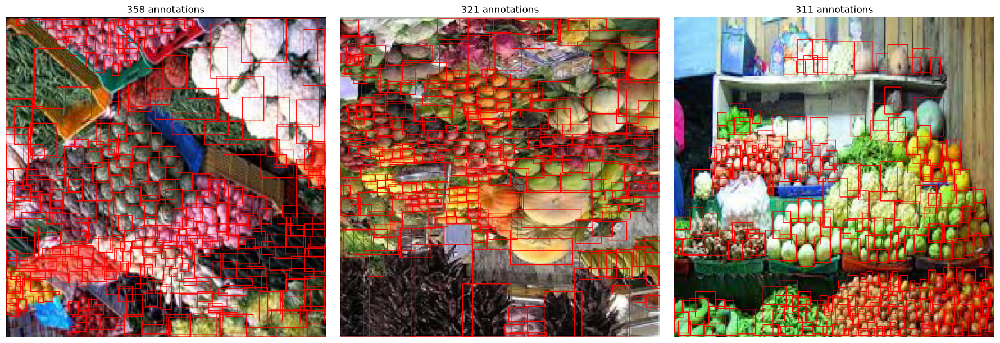

In [35]:
from pathlib import Path
import matplotlib.pyplot as plt
import cv2

images_dir = Path("../data/raw/GarbageDataset/images")
labels_dir = Path("../data/raw/GarbageDataset/labels")

# Find the image with the highest number of annotations
label_files = list(labels_dir.glob("*.txt"))

annotation_counts = []

for label_file in label_files:
    count = sum(
        1 for line in label_file.read_text().splitlines()
        if line.strip()
    )
    annotation_counts.append((label_file.stem, count))

# Sort by annotation count
annotation_counts.sort(key=lambda x: x[1], reverse=True)

# Display the top 3 images
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (image_name, count) in zip(axes, annotation_counts[:3]):

    image_path = images_dir / f"{image_name}.jpg"
    label_path = labels_dir / f"{image_name}.txt"

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    for line in label_path.read_text().splitlines():

        values = line.split()

        if len(values) != 5:
            continue

        class_id, xc, yc, w, h = map(float, values)

        x1 = int((xc - w / 2) * image.shape[1])
        y1 = int((yc - h / 2) * image.shape[0])
        x2 = int((xc + w / 2) * image.shape[1])
        y2 = int((yc + h / 2) * image.shape[0])

        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 1)

    ax.imshow(image)
    ax.set_title(f"{count} annotations")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 16. Bounding Box Overlap Analysis

We calculate the Intersection over Union (IoU) between bounding-box pairs in the same image to understand how frequently annotated objects overlap.

In [36]:
from itertools import combinations
from pathlib import Path
import numpy as np

labels_dir = Path("../data/raw/GarbageDataset/labels")

def calculate_iou(box1, box2):
    """
    Calculate Intersection over Union between two YOLO boxes.
    Boxes are represented as (x_center, y_center, width, height).
    """

    x1_min = box1[0] - box1[2] / 2
    y1_min = box1[1] - box1[3] / 2
    x1_max = box1[0] + box1[2] / 2
    y1_max = box1[1] + box1[3] / 2

    x2_min = box2[0] - box2[2] / 2
    y2_min = box2[1] - box2[3] / 2
    x2_max = box2[0] + box2[2] / 2
    y2_max = box2[1] + box2[3] / 2

    intersection_width = max(0, min(x1_max, x2_max) - max(x1_min, x2_min))
    intersection_height = max(0, min(y1_max, y2_max) - max(y1_min, y2_min))

    intersection = intersection_width * intersection_height

    area1 = box1[2] * box1[3]
    area2 = box2[2] * box2[3]

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


overlap_values = []

for label_file in labels_dir.glob("*.txt"):

    boxes = []

    for line in label_file.read_text().splitlines():

        values = line.split()

        if len(values) != 5:
            continue

        class_id, xc, yc, w, h = map(float, values)

        if w > 0 and h > 0:
            boxes.append((xc, yc, w, h))

    # Compare every pair of boxes in the image
    for box1, box2 in combinations(boxes, 2):

        iou = calculate_iou(box1, box2)

        if iou > 0:
            overlap_values.append(iou)

print("OVERLAP ANALYSIS")
print("------------------------------")
print("Overlapping box pairs:", len(overlap_values))

if overlap_values:
    print("Mean IoU:", round(np.mean(overlap_values), 4))
    print("Median IoU:", round(np.median(overlap_values), 4))
    print("Maximum IoU:", round(np.max(overlap_values), 4))

OVERLAP ANALYSIS
------------------------------
Overlapping box pairs: 115492
Mean IoU: 0.0813
Median IoU: 0.0453
Maximum IoU: 0.9974


In [37]:
from itertools import combinations
from pathlib import Path

high_overlap_pairs = []

for label_file in labels_dir.glob("*.txt"):

    boxes = []

    for line in label_file.read_text().splitlines():

        values = line.split()

        if len(values) != 5:
            continue

        class_id, xc, yc, w, h = map(float, values)

        if w > 0 and h > 0:
            boxes.append((int(class_id), xc, yc, w, h))

    for box1, box2 in combinations(boxes, 2):

        iou = calculate_iou(box1[1:], box2[1:])

        if iou > 0.9:
            high_overlap_pairs.append({
                "image": label_file.stem,
                "class_1": box1[0],
                "class_2": box2[0],
                "IoU": round(iou, 4)
            })

print("Highly overlapping pairs:", len(high_overlap_pairs))

for pair in high_overlap_pairs[:10]:
    print(pair)

Highly overlapping pairs: 56
{'image': 'plastic624_jpg.rf.5867ea61e9d1701550927c1bc0c667c8', 'class_1': 5, 'class_2': 2, 'IoU': 0.9936}
{'image': 'paper1898_jpg.rf.df7551e7b72a8e74d10a791e376aa693', 'class_1': 4, 'class_2': 4, 'IoU': 0.9137}
{'image': 'paper2320_jpg.rf.bb094a2ce325519ccb563cf0fb82668c', 'class_1': 1, 'class_2': 1, 'IoU': 0.9644}
{'image': 'paper2088_jpg.rf.c334eedd46c71a73b4c09254eafa226b', 'class_1': 1, 'class_2': 1, 'IoU': 0.9861}
{'image': 'plastic751_jpg.rf.1d734b63cb62ec1162b35f7d71ca2e49', 'class_1': 5, 'class_2': 5, 'IoU': 0.9394}
{'image': 'plastic198_jpg.rf.43e780fe08bf4815e919573bfbfaac03', 'class_1': 5, 'class_2': 5, 'IoU': 0.9032}
{'image': 'biodegradable748_jpg.rf.3aba23ce65f546f4a6878a3637ff9d87', 'class_1': 0, 'class_2': 0, 'IoU': 0.9504}
{'image': 'paper59_jpg.rf.e8a251fd9a01cdc40dceb37c37d551d3', 'class_1': 4, 'class_2': 1, 'IoU': 0.9907}
{'image': 'paper1086_jpg.rf.86bbf3fa2aaf0455d95128941bb05511', 'class_1': 1, 'class_2': 1, 'IoU': 0.9244}
{'image':

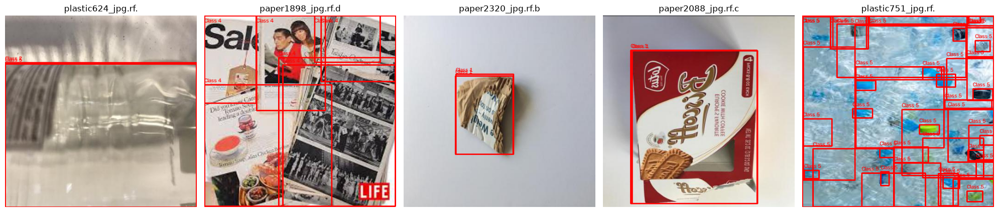

In [38]:
import matplotlib.pyplot as plt
import cv2

images_dir = Path("../data/raw/GarbageDataset/images")

# Get the first 5 unique images with high overlap
selected_images = list(dict.fromkeys(
    pair["image"] for pair in high_overlap_pairs
))[:5]

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, image_name in zip(axes, selected_images):

    image_path = images_dir / f"{image_name}.jpg"
    label_path = labels_dir / f"{image_name}.txt"

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    for line in label_path.read_text().splitlines():

        values = line.split()

        if len(values) != 5:
            continue

        class_id, xc, yc, w, h = map(float, values)

        x1 = int((xc - w / 2) * 416)
        y1 = int((yc - h / 2) * 416)
        x2 = int((xc + w / 2) * 416)
        y2 = int((yc + h / 2) * 416)

        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

        cv2.putText(
            image,
            f"Class {int(class_id)}",
            (x1, max(y1 - 5, 15)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.4,
            (255, 0, 0),
            1
        )

    ax.imshow(image)
    ax.set_title(image_name[:18])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [42]:
import numpy as np
import pandas as pd
from pathlib import Path

labels_dir = Path("../data/raw/GarbageDataset/labels")

class_ids = [0, 1, 2, 3, 4, 5]

image_names = []
multi_labels = []

for label_file in sorted(labels_dir.glob("*.txt")):

    present_classes = set()

    for line in label_file.read_text().splitlines():

        values = line.split()

        if len(values) != 5:
            continue

        class_id = int(float(values[0]))

        if class_id in class_ids:
            present_classes.add(class_id)

    image_names.append(label_file.stem)

    multi_labels.append([
        1 if class_id in present_classes else 0
        for class_id in class_ids
    ])

# Convert to NumPy array
multi_labels = np.array(multi_labels)

# Create a readable table
class_columns = [f"class_{i}" for i in class_ids]

multi_label_df = pd.DataFrame(
    multi_labels,
    columns=class_columns
)

multi_label_df.insert(0, "image_name", image_names)

print("Multi-label matrix shape:", multi_labels.shape)
print("\nFirst 5 rows:")
display(multi_label_df.head())

print("\nNumber of images containing each class:")
print(multi_label_df[class_columns].sum())

Multi-label matrix shape: (10464, 6)

First 5 rows:


,image_name,class_0,class_1,class_2,class_3,class_4,class_5
0,biodegradable1000_jpg.rf.9407ff66b4ccd9f8eb554...,1,0,0,0,0,0
1,biodegradable1001_jpg.rf.7903fa84ae12e27e6ee01...,1,0,0,0,0,0
2,biodegradable1002_jpg.rf.b9ead478ce5c0cfe58bc8...,1,0,0,0,0,0
3,biodegradable1003_jpg.rf.f77cec0a34271415dcead...,1,0,0,0,0,0
4,biodegradable1004_jpg.rf.645d319975e53c260b201...,1,0,0,0,0,0



Number of images containing each class:
class_0    2287
class_1    1502
class_2    2684
class_3    1898
class_4    1768
class_5    1464
dtype: int64


## 17. Train, Validation and Test Split

We use iterative multi-label stratification to distribute images across training, validation and test sets while preserving class representation.

In [43]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
import numpy as np

# First split: 90% development, 10% testing
split_1 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.10,
    random_state=42
)

development_indices, test_indices = next(
    split_1.split(np.zeros(len(multi_labels)), multi_labels)
)

# Second split: 70% training, 20% validation overall
development_labels = multi_labels[development_indices]

split_2 = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=2/9,
    random_state=42
)

train_relative, val_relative = next(
    split_2.split(np.zeros(len(development_labels)), development_labels)
)

train_indices = development_indices[train_relative]
val_indices = development_indices[val_relative]

# Get image names for each set
train_images = [image_names[i] for i in train_indices]
val_images = [image_names[i] for i in val_indices]
test_images = [image_names[i] for i in test_indices]

# Display split sizes
print("DATASET SPLIT")
print("----------------------")
print("Training:", len(train_images))
print("Validation:", len(val_images))
print("Testing:", len(test_images))
print("Total:", len(train_images) + len(val_images) + len(test_images))

DATASET SPLIT
----------------------
Training: 7305
Validation: 2113
Testing: 1046
Total: 10464


CLASS DISTRIBUTION ACROSS DATASETS
----------------------------------


,Class,Training,Validation,Testing
0,class_0,1601,457,229
1,class_1,1052,300,150
2,class_2,1878,537,269
3,class_3,1328,380,190
4,class_4,1237,354,177
5,class_5,1025,293,146


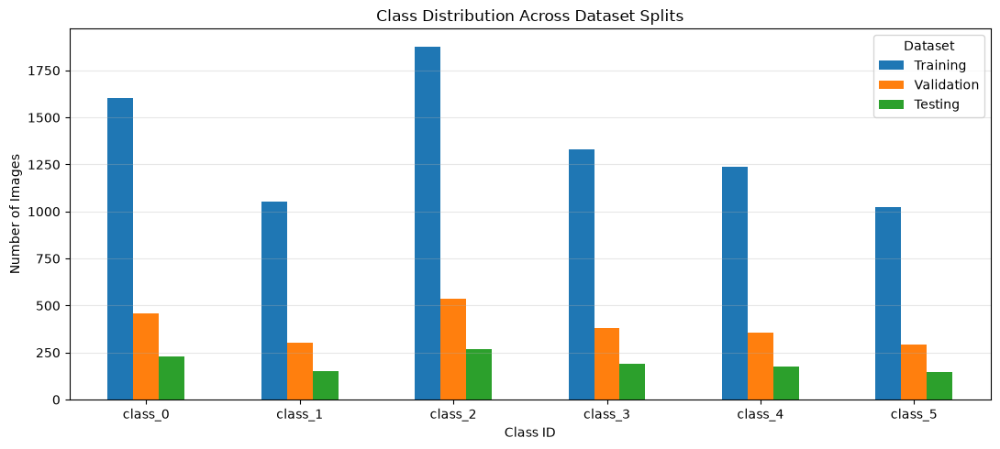

In [47]:
# Get multi-label information for each split
train_labels = multi_labels[train_indices]
val_labels = multi_labels[val_indices]
test_labels = multi_labels[test_indices]

# Count images containing each class
distribution = pd.DataFrame({
    "Class": class_columns,
    "Training": train_labels.sum(axis=0),
    "Validation": val_labels.sum(axis=0),
    "Testing": test_labels.sum(axis=0)
})

print("CLASS DISTRIBUTION ACROSS DATASETS")
print("----------------------------------")
display(distribution)


distribution.set_index("Class").plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [48]:
train_set = set(train_images)
val_set = set(val_images)
test_set = set(test_images)

print("DATA LEAKAGE CHECK")
print("--------------------------")

print("Train ∩ Validation:", len(train_set & val_set))
print("Train ∩ Test:", len(train_set & test_set))
print("Validation ∩ Test:", len(val_set & test_set))

print("\nAll images accounted for:",
      len(train_set | val_set | test_set) == len(image_names))

DATA LEAKAGE CHECK
--------------------------
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

All images accounted for: True


In [49]:
import shutil
from pathlib import Path

# Source folders
raw_images = Path("../data/raw/GarbageDataset/images")
raw_labels = Path("../data/raw/GarbageDataset/labels")

# Destination folder
processed_dir = Path("../data/processed/GarbageDataset")

# Create dataset folders
splits = {
    "train": train_images,
    "val": val_images,
    "test": test_images
}

for split_name, image_list in splits.items():

    image_dest = processed_dir / split_name / "images"
    label_dest = processed_dir / split_name / "labels"

    image_dest.mkdir(parents=True, exist_ok=True)
    label_dest.mkdir(parents=True, exist_ok=True)

    for image_name in image_list:

        # Copy image
        image_source = raw_images / f"{image_name}.jpg"
        shutil.copy2(
            image_source,
            image_dest / image_source.name
        )

        # Copy corresponding label
        label_source = raw_labels / f"{image_name}.txt"
        shutil.copy2(
            label_source,
            label_dest / label_source.name
        )

    print(f"{split_name}: {len(image_list)} images and labels copied.")

print("\nDataset preparation completed!")

train: 7305 images and labels copied.
val: 2113 images and labels copied.
test: 1046 images and labels copied.

Dataset preparation completed!


In [50]:
from pathlib import Path

processed_dir = Path("../data/processed/GarbageDataset")

for split in ["train", "val", "test"]:

    image_dir = processed_dir / split / "images"
    label_dir = processed_dir / split / "labels"

    images = list(image_dir.glob("*.jpg"))
    labels = list(label_dir.glob("*.txt"))

    image_stems = {f.stem for f in images}
    label_stems = {f.stem for f in labels}

    print(f"\n{split.upper()}")
    print("-------------------")
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Missing labels:", len(image_stems - label_stems))
    print("Missing images:", len(label_stems - image_stems))


TRAIN
-------------------
Images: 7305
Labels: 7305
Missing labels: 0
Missing images: 0

VAL
-------------------
Images: 2113
Labels: 2113
Missing labels: 0
Missing images: 0

TEST
-------------------
Images: 1046
Labels: 1046
Missing labels: 0
Missing images: 0


In [51]:
from pathlib import Path

processed_dir = Path("../data/processed/GarbageDataset")

removed_annotations = 0
cleaned_files = 0

for split in ["train", "val", "test"]:

    label_dir = processed_dir / split / "labels"

    for label_file in label_dir.glob("*.txt"):

        valid_lines = []

        for line in label_file.read_text().splitlines():

            values = line.split()

            if len(values) != 5:
                continue

            class_id, xc, yc, width, height = map(float, values)

            valid = (
                class_id.is_integer()
                and 0 <= class_id <= 5
                and 0 <= xc <= 1
                and 0 <= yc <= 1
                and width > 0
                and height > 0
                and width <= 1
                and height <= 1
                and xc - width / 2 >= 0
                and yc - height / 2 >= 0
                and xc + width / 2 <= 1
                and yc + height / 2 <= 1
            )

            if valid:
                valid_lines.append(line)
            else:
                removed_annotations += 1

        original_lines = [
            line for line in label_file.read_text().splitlines()
            if line.strip()
        ]

        if len(valid_lines) != len(original_lines):
            cleaned_files += 1

        label_file.write_text(
            "\n".join(valid_lines) + ("\n" if valid_lines else "")
        )

print("ANNOTATION CLEANING")
print("----------------------------")
print("Invalid annotations removed:", removed_annotations)
print("Files containing invalid annotations:", cleaned_files)

ANNOTATION CLEANING
----------------------------
Invalid annotations removed: 17
Files containing invalid annotations: 17


In [52]:
from pathlib import Path

processed_dir = Path("../data/processed/GarbageDataset")

remaining_invalid = 0
total_annotations = 0

for split in ["train", "val", "test"]:

    label_dir = processed_dir / split / "labels"

    for label_file in label_dir.glob("*.txt"):

        for line in label_file.read_text().splitlines():

            if not line.strip():
                continue

            values = line.split()

            if len(values) != 5:
                remaining_invalid += 1
                continue

            class_id, xc, yc, w, h = map(float, values)

            valid = (
                class_id.is_integer()
                and 0 <= class_id <= 5
                and 0 <= xc <= 1
                and 0 <= yc <= 1
                and 0 < w <= 1
                and 0 < h <= 1
                and xc - w / 2 >= 0
                and yc - h / 2 >= 0
                and xc + w / 2 <= 1
                and yc + h / 2 <= 1
            )

            total_annotations += 1

            if not valid:
                remaining_invalid += 1

print("CLEANING VERIFICATION")
print("----------------------------")
print("Remaining annotations:", total_annotations)
print("Remaining invalid annotations:", remaining_invalid)

CLEANING VERIFICATION
----------------------------
Remaining annotations: 74073
Remaining invalid annotations: 0


In [59]:
from pathlib import Path

dataset_root = Path(data_config["path"])

print("DATASET CONFIGURATION CHECK")
print("------------------------------")

for split in ["train", "val", "test"]:

    image_dir = dataset_root / data_config[split]

    exists = image_dir.exists()
    image_count = len(list(image_dir.glob("*.jpg"))) if exists else 0

    print(f"{split}:")
    print("  Directory exists:", exists)
    print("  Images:", image_count)

print("\nNumber of classes:", data_config["nc"])
print("Class names:", data_config["names"])

DATASET CONFIGURATION CHECK
------------------------------
train:
  Directory exists: True
  Images: 7305
val:
  Directory exists: True
  Images: 2113
test:
  Directory exists: True
  Images: 1046

Number of classes: 6
Class names: {0: 'biodegradable', 1: 'cardboard', 2: 'glass', 3: 'metal', 4: 'paper', 5: 'plastic'}



## 18. Dataset Analysis Summary

### Dataset Overview
- Total images: 10,464
- Image resolution: 416 × 416
- Number of classes: 6
- Total original annotations: 74,090
- Valid annotations after cleaning: 74,073
- Annotation format: YOLO

### Dataset Split

| Dataset | Images | Percentage |
|---|---:|---:|
| Training | 7,305 | 69.80% |
| Validation | 2,113 | 20.19% |
| Testing | 1,046 | 10.00% |

Multi-label stratification was used to preserve class representation across splits.

### Data Quality
- Every image has a corresponding label file.
- No duplicate image files were detected.
- No data leakage was detected between splits.
- 17 invalid bounding-box annotations were removed.
- All remaining bounding boxes passed validation.

### Dataset Characteristics
- The dataset contains both single-class and multi-class images.
- Class 0 has the highest number of bounding-box annotations.
- Object sizes vary considerably between classes.
- Small objects may present a detection challenge.
- Some bounding boxes overlap.

### Class Names
The six class names were inferred from image filename prefixes because official class documentation was not supplied.

### Conclusion
The dataset has been analyzed, split, cleaned and organized for object detection experiments. The original dataset remains unchanged.


In [60]:
import torch
import ultralytics
from ultralytics import YOLO

print("PyTorch version:", torch.__version__)
print("Ultralytics version:", ultralytics.__version__)

print("MPS available:", torch.backends.mps.is_available())
print("MPS built:", torch.backends.mps.is_built())

PyTorch version: 2.15.0
Ultralytics version: 8.4.202
MPS available: True
MPS built: True


In [61]:
# Load pretrained YOLOv8 Small weights
model = YOLO("yolov8s.pt")

print("YOLOv8s loaded successfully!")

YOLOv8s loaded successfully!


In [62]:
from pathlib import Path

sample_image = next(
    Path("../data/processed/GarbageDataset/train/images").glob("*.jpg")
)

results = model.predict(
    source=str(sample_image),
    imgsz=416,
    device="mps",
    verbose=False
)

print("Image:", sample_image.name)
print("Inference successful!")
print("Detected objects:", len(results[0].boxes))

Image: glass1060_jpg.rf.376e0c90f28fcb6624a7e5405e772734.jpg
Inference successful!
Detected objects: 1


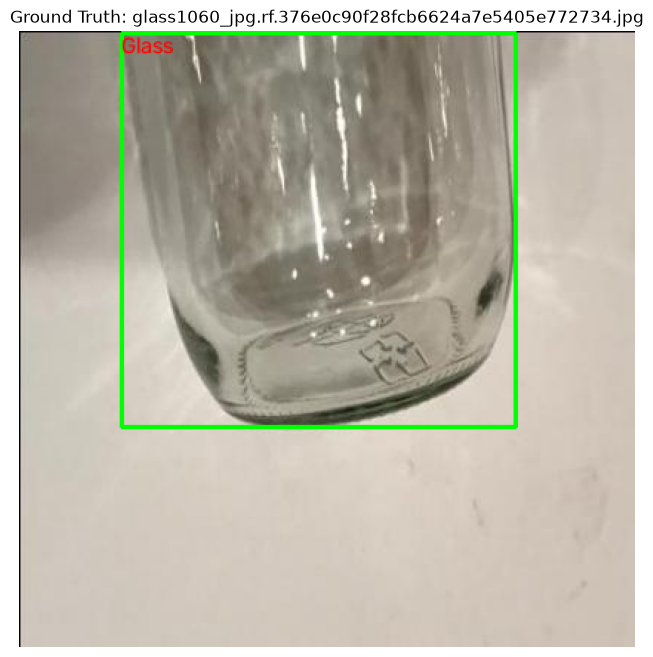

Image dimensions: 416 x 416
Number of ground-truth objects: 1


In [63]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Select one training image
image_path = next(
    Path("../data/processed/GarbageDataset/train/images").glob("*.jpg")
)

# Find its corresponding label
label_path = (
    Path("../data/processed/GarbageDataset/train/labels")
    / f"{image_path.stem}.txt"
)

# Load image
image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Image dimensions
height, width, _ = image.shape

# Class names
class_names = {
    0: "Biodegradable",
    1: "Cardboard",
    2: "Glass",
    3: "Metal",
    4: "Paper",
    5: "Plastic"
}

# Read YOLO annotations
with open(label_path, "r") as file:
    annotations = file.readlines()

# Draw bounding boxes
for annotation in annotations:

    class_id, xc, yc, w, h = map(float, annotation.split())

    # Convert normalized coordinates to pixels
    x1 = int((xc - w / 2) * width)
    y1 = int((yc - h / 2) * height)
    x2 = int((xc + w / 2) * width)
    y2 = int((yc + h / 2) * height)

    # Draw rectangle
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

    # Add class name
    label = class_names[int(class_id)]

    cv2.putText(
        image,
        label,
        (x1, max(y1 - 5, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        1
    )

# Display image
plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.title(f"Ground Truth: {image_path.name}")
plt.axis("off")
plt.show()

print("Image dimensions:", width, "x", height)
print("Number of ground-truth objects:", len(annotations))

In [66]:
from pathlib import Path
from ultralytics import YOLO

# Dataset configuration
data_yaml_path = Path("../data/processed/GarbageDataset/data.yaml")

# Load pretrained YOLOv8 Small
model = YOLO("yolov8s.pt")

# Start training
train_results = model.train(
    data=str(data_yaml_path),

    # Training settings
    epochs=10,
    imgsz=416,
    batch=16,
    device="mps",

    # Model settings
    pretrained=True,
    optimizer="auto",

    # Augmentation settings
    degrees=10,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    flipud=0.0,
    hsv_h=0.015,
    hsv_s=0.5,
    hsv_v=0.3,
    mosaic=1.0,
    mixup=0.0,
    close_mosaic=10,

    # Other settings
    patience=15,
    workers=2,
    seed=42,
    plots=True,
    save=True,

    # Output location
    project="../results/training",
    name="yolov8s_garbage_v1"
)


Ultralytics 8.4.202 🚀 Python-3.12.14 torch-2.15.0 MPS (Apple M5)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../data/processed/GarbageDataset/data.yaml, degrees=10, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.3, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_garbage_v1, nbs=64, nms=None, opset=None, optimize=False

/Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding d

       1/10      4.39G      1.516      2.145      1.503        104        416: 100% ━━━━━━━━━━━━ 457/457 1.7it/s 4:350.8ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 67/67 1.8it/s 36.5s0.5ss
                   all       2113      15654      0.391      0.343      0.309      0.161

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


/Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding d

       2/10      4.38G      1.575       1.96      1.558        106        416: 100% ━━━━━━━━━━━━ 457/457 1.5it/s 5:130.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 67/67 1.7it/s 40.4s0.6ss
                   all       2113      15654      0.395      0.316      0.278      0.144

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


/Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding d

... (11 outputs left out)

/Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding d

       9/10      4.39G       1.31      1.254      1.373         21        416: 100% ━━━━━━━━━━━━ 457/457 1.3it/s 5:430.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 67/67 1.7it/s 39.2s0.6ss
                   all       2113      15654      0.653      0.504      0.579      0.362

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


/Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding d

      10/10      5.38G      1.268      1.177      1.355         49        416: 100% ━━━━━━━━━━━━ 457/457 1.4it/s 5:240.6ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 67/67 1.7it/s 39.5s0.6ss
                   all       2113      15654       0.65      0.538      0.604       0.39

10 epochs completed in 1.001 hours.
Optimizer stripped from /Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/notebooks/runs/results/training/yolov8s_garbage_v1/weights/last.pt, 22.5MB
Optimizer stripped from /Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/notebooks/runs/results/training/yolov8s_garbage_v1/weights/best.pt, 22.5MB

Validating /Users/shreyas/Desktop/THWS/2nd sem/Computer Vision/Portfolio 1/notebooks/runs/results/training/yolov8s_garbage_v1/weights/best.pt...
Ultralytics 8.4.202 🚀 Python-3.12.14 torch-2.15.0 MPS (Apple M5)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs